# 3. From a bond to a chain: spacetime dynamics

**Author:** Aditya Banerjee  
**Thesis:** *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona, 2026

The thesis releases a doubly occupied site into an otherwise empty chain. Because total occupation is conserved, the evolution stays in the two-particle sector. We calculate the occupation at every site and compare it with a single excitation.

**Thesis source:** Section 3.8.2, Eqs. (46), (48), (56), Figures 4–5. Descriptions below are adapted from these sections;
equation numbers refer to the thesis. **Code source:** [`heff2_spacetime.py`](../scripts/heff2_spacetime.py).

**Steps:** parameters → bond terms → fixed-number matrix → initial state → evolution → density maps.

Run the numbered sections from top to bottom. Longer derivations and implementation
comparisons are at the end. These are theoretical calculations, not experimental data.

## 1. Import libraries

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Run from the repository root or from notebooks/.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "scripts").is_dir() and (p / "data").is_dir())
DATA = ROOT / "data"
SAVE_FIGURES = False
STYLE = {"font.size": 11}


def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "notebook_outputs"
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f"{name}.png", dpi=160)
    display(fig)
    plt.close(fig)

## 2. Set the source chain and drive parameters

**Symbols used in the code**

| Thesis symbol | Code name | Meaning |
|---|---|---|
| $C_{ab}$ | `C00`, `C01`, … | Interaction-shift parameters |
| $\Omega_\alpha,\Omega_\beta$ | `Om_a`, `Om_b` | Laser-coupling amplitudes |
| $\omega'$ | `wp` or `WP` | Drive rate |
| $A$ | `A` | Detuning-modulation amplitude |
| $\kappa=A/\omega'$ | `kappa` or `kap` | Dimensionless modulation index |
| $L$ | `L` | Number of sites |
| $N$ | `N` | Total occupation quanta |

The bare pair energies are $2C_{00},C_{01},2C_{11},C_{02},C_{12},2C_{22}$.
The $C$, $\Omega$, $\omega'$, and $A$ values use one **native numerical rate unit**.
$J_\ell(\kappa)$ is the Bessel function of integer order $\ell$.

Evolution uses $K=H/(\hbar\omega_{\rm ref})$ and $\tau=\omega_{\rm ref}t$,
with $[\hbar\omega_{\rm ref}]={\rm J}$ and $[\tau]=1$; the reference is one
native rate unit. This preserves the source numbers without claiming a calibrated
microsecond axis while the cycles-versus-radians convention remains unresolved.

In [3]:
C00, C01, C11 = 0.0, 20.0, 15.0
C02, C12, C22 = 2 * C11, 45.0, 55.0
Om_a, Om_b = 1.0, 1.0
WP, A, N_RES = 40.0, 48.0, 1
COMPENSATE_11BLOCK = True
LMAX = 60
ells = np.arange(-LMAX, LMAX + 1)
d = 3

L, usePBC = 10, False
TMAX, NT = 600.0, 900
times = np.linspace(0, TMAX, NT)

## 3. Calculate the sideband sums

Thesis Eq. (41) sums the virtual sidebands.
We write $S(X)/\Omega_\beta^2$ as `ss(X)`:
$$S(X)/\Omega_\beta^2=\sum_\ell\frac{J_\ell(\kappa)^2}{X+\widetilde\nu+\ell\omega'}.$$
Each denominator is a rate, so the sum has inverse-rate units. `LMAX` sets the finite cutoff.

In [4]:
kap = A / WP
nu = 2 * C11 - C02 - N_RES * WP
Jl = jv(ells, kap)


def ss(dconst):
    den = dconst + nu + ells * WP
    if np.any(np.abs(den) < 1e-9):
        raise ZeroDivisionError("resonant Stark denominator at WP=%g" % WP)
    return float(np.sum(Jl**2 / den))

## 4. Build the diagonal energies

Thesis Eq. (42) gives the AC Stark shifts.
For example, $E_{00}=-2\Omega_\alpha^2/(C_{01}-2C_{00})$.
The following cell evaluates all nine entries. **Source assumption:** the optional
$E_{11}\leftarrow E_{20}$ compensation is an imposed shift, not a self-consistent retuning.

In [5]:
E = {}
E["00"] = -2 * Om_a**2 / (C01 - 2 * C00)
E["01"] = Om_a**2 / (C01 - 2 * C00) - Om_a**2 / (2 * C11 - C01) - Om_b**2 * ss(C02 - C01)
E["02"] = Om_b**2 * ss(C02 - C01) - Om_a**2 / (C12 - C02)
E["10"] = E["01"]
E["11"] = 2 * Om_a**2 / (2 * C11 - C01) - 2 * Om_b**2 * ss(C12 - 2 * C11)
E["12"] = Om_a**2 / (C12 - C02) + Om_b**2 * ss(C12 - 2 * C11) - Om_b**2 * ss(2 * C22 - C12)
E["20"] = E["02"]
E["21"] = E["12"]
E["22"] = 2 * Om_b**2 * ss(2 * C22 - C12)
if COMPENSATE_11BLOCK:
    E["11"] += E["20"] - E["11"]

## 5. Calculate the four exchange amplitudes

Thesis Eq. (43) connects
$01\leftrightarrow10$, $11\leftrightarrow20$, $02\leftrightarrow11$, and $12\leftrightarrow21$.
For example,
$$g_1=\Omega_\alpha^2\left[\frac1{C_{01}-2C_{00}}-\frac1{2C_{11}-C_{01}}\right].$$
The signed rates are kept; the reverse matrix elements are their complex conjugates.

In [6]:
g1 = Om_a**2 * (1.0 / (C01 - 2 * C00) - 1.0 / (2 * C11 - C01))
pref = Om_a * Om_b * (1.0 / (2 * C11 - C01) - 1.0 / (C12 - C02))
g2 = pref * jv(N_RES, kap)
g3 = pref * jv(N_RES, kap)
Sig = 1.0 / (C12 - 2 * C11 + nu + ells * WP) - 1.0 / (2 * C22 - C12 + nu + ells * WP)
g4 = Om_b**2 * float(np.sum(Jl * jv(ells, kap) * Sig))

Eb = np.array([[E["%d%d" % (a, b)] for b in range(d)] for a in range(d)])
gs = (g1, g2, g3, g4)
print("Signed exchange rates:", np.array(gs))

Signed exchange rates: [-0.05     0.01661  0.01661 -0.01012]


## 6. Build the conserved-number sector

The chain operator is
$$H=\sum_{j=0}^{L-2}H_{{\rm eff},j,j+1}^{(2)}.$$
For the thesis initial state $|0,0,0,0,2,0,0,0,0,0\rangle$, $N=2$ and the sector
contains 55 configurations. Open ends and normalized occupation states are assumed.
`drive` and `anyon` below are names for **assigned matrix phases**; their gauge
relation does not establish that arbitrary phases are physically achievable.

In [7]:
configs = np.array(list(product(range(d), repeat=L)), dtype=np.int8)
Nvec = configs.sum(axis=1).astype(int)
PW = np.array([d ** (L - 1 - j) for j in range(L)], dtype=np.int64)
DIMFULL = d**L
BONDS = [(j, j + 1) for j in range(L - 1)]
if usePBC:
    BONDS.append((L - 1, 0))


def sector(N):
    rows = np.where(Nvec == N)[0]
    pos = np.full(DIMFULL, -1, dtype=np.int64)
    pos[rows] = np.arange(len(rows))
    return rows, pos, configs[rows]

In [8]:
def phases_of(mode, ang, j, alpha=0.0, beta=0.0):
    """Assigned numerical patterns; physical reachability is not established."""
    if mode == "drive":
        a, b = 0.0, ang
        return -a, b - 2 * a, a - 2 * b, -b
    if mode == "anyon":
        return 0.0, ang, 0.0, ang
    a_j, a_j1 = (j + 1) * alpha, (j + 2) * alpha
    b_j, b_j1 = (j + 1) * beta, (j + 2) * beta
    return a_j - a_j1, b_j - a_j1, a_j - b_j1, b_j - b_j1

In [9]:
def sector_H(N, Eb, gs, mode, phi, alpha=0.0, beta=0.0):
    """Dense H_eff^(2) restricted to sector N (exact, since [H,N]=0)."""
    rows, pos, cfg = sector(N)
    dim = len(rows)
    g1, g2, g3, g4 = gs
    H = np.zeros((dim, dim), dtype=complex)
    diag = np.zeros(dim)
    for jL, jR in BONDS:
        diag += Eb[cfg[:, jL], cfg[:, jR]]
    H[np.arange(dim), np.arange(dim)] = diag
    for jb, (jL, jR) in enumerate(BONDS):
        th = phases_of(mode, phi, jb, alpha, beta)
        for (a, b), (a2, b2), g, t in [
            ((0, 1), (1, 0), g1, th[0]),
            ((1, 1), (2, 0), g2, th[1]),
            ((0, 2), (1, 1), g3, th[2]),
            ((1, 2), (2, 1), g4, th[3]),
        ]:
            if g == 0.0:
                continue
            amp = g * np.exp(1j * t)
            sel = np.where((cfg[:, jL] == a) & (cfg[:, jR] == b))[0]
            if sel.size == 0:
                continue
            tgt = pos[rows[sel] + (a2 - a) * PW[jL] + (b2 - b) * PW[jR]]
            H[tgt, sel] += amp
            H[sel, tgt] += np.conj(amp)
    return H, cfg, rows, pos

## 7. Evolve the initial occupation state

For configuration $s$, let $n_j(s)$
be its known occupation at site $j$. The thesis density observable is
$$\langle n_j(\tau)\rangle=\sum_s|\psi_s(\tau)|^2n_j(s).$$
It is dimensionless, lies between zero and two, and sums over sites to the conserved $N$.
The source function calculates this by multiplying probabilities by the configuration array.

In [10]:
def evolve_density(N, cfgstate, Eb, gs, mode, phi, times, alpha=0.0, beta=0.0):
    """<n_j(t)> for the Fock initial state cfgstate, exactly."""
    H, cfg, rows, pos = sector_H(N, Eb, gs, mode, phi, alpha, beta)
    assert np.allclose(H, H.conj().T, atol=1e-13), "sector H not Hermitian"
    ev, V = np.linalg.eigh(H)
    i0 = pos[int(np.dot(cfgstate, PW))]
    assert i0 >= 0, "initial state is not in sector N=%d" % N
    psi0 = np.zeros(len(rows), dtype=complex)
    psi0[i0] = 1.0
    c = V.conj().T @ psi0
    psit = (np.exp(-1j * np.outer(times, ev)) * c) @ V.T  # (Nt, dim)
    p = np.abs(psit) ** 2
    return p @ cfg.astype(float), ev  # (Nt, L)

In [11]:
doublon = np.zeros(L, dtype=int)
doublon[L // 2 - 1] = 2
single = doublon // 2
density_pair, _ = evolve_density(2, doublon, Eb, gs, "anyon", 0.0, times)
density_single, _ = evolve_density(1, single, Eb, gs, "anyon", 0.0, times)
print("Two-particle sector dimension:", len(sector(2)[0]))
print("Initial two-particle occupations:", density_pair[0])

Two-particle sector dimension: 55
Initial two-particle occupations: [0. 0. 0. 0. 2. 0. 0. 0. 0. 0.]


## 8. Plot the single-excitation and doublon maps

This follows the comparison in Figure 4. Colour gives occupation, and the time axis uses the declared dimensionless convention.

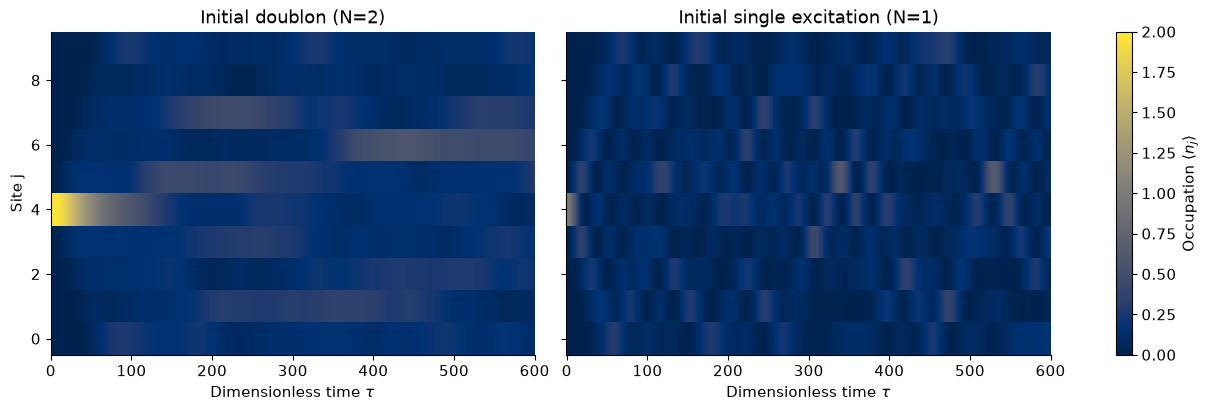

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
for ax, density, title in zip(
    axes,
    [density_pair, density_single],
    ["Initial doublon (N=2)", "Initial single excitation (N=1)"],
):
    mesh = ax.pcolormesh(
        times, np.arange(L), density.T, shading="nearest", cmap="cividis", vmin=0, vmax=2
    )
    ax.set(title=title, xlabel=r"Dimensionless time $\tau$")
axes[0].set_ylabel("Site j")
fig.colorbar(mesh, ax=axes, label=r"Occupation $\langle n_j\rangle$")
show_figure(fig, "03_single_and_doublon")

## 9. Compare assigned statistical phases

Figure 5 motivates comparing phase-dependent density patterns. These are predictions of assigned finite matrices; the thesis’s physical phase restriction still applies.

In [13]:
angles = [0.0, np.pi / 2, np.pi]
phase_densities = [evolve_density(2, doublon, Eb, gs, "anyon", angle, times)[0] for angle in angles]

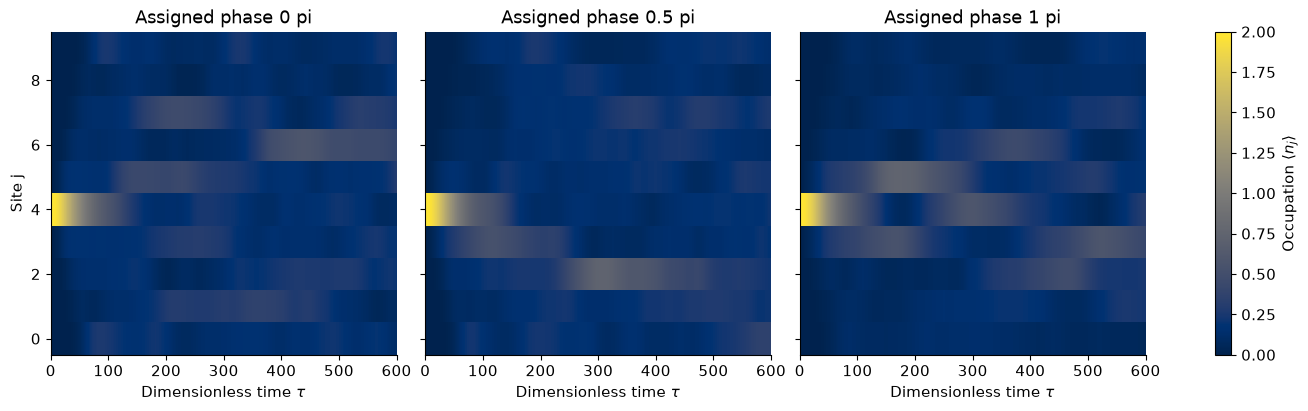

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained", sharey=True)
for ax, angle, density in zip(axes, angles, phase_densities):
    mesh = ax.pcolormesh(
        times, np.arange(L), density.T, shading="nearest", cmap="cividis", vmin=0, vmax=2
    )
    ax.set(title=f"Assigned phase {angle/np.pi:g} pi", xlabel=r"Dimensionless time $\tau$")
axes[0].set_ylabel("Site j")
fig.colorbar(mesh, ax=axes, label=r"Occupation $\langle n_j\rangle$")
show_figure(fig, "03_assigned_phases")

## 10. Read the maps and check conservation

The single excitation spreads through the exchange channel. The doublon also accesses the Floquet-assisted channels. Each displayed trajectory must preserve its initial total occupation.

In [15]:
for density, N in [(density_single, 1), (density_pair, 2), *[(x, 2) for x in phase_densities]]:
    error = np.max(abs(density.sum(axis=1) - N))
    assert error < 1e-11
    print(f"N={N}: largest total-occupation error = {error:.2e}")

N=1: largest total-occupation error = 1.11e-15
N=2: largest total-occupation error = 6.00e-15
N=2: largest total-occupation error = 6.00e-15
N=2: largest total-occupation error = 2.00e-15
N=2: largest total-occupation error = 5.55e-15


## Appendix — detailed derivations and verification

The main calculation is complete. This appendix retains the symbolic steps, conventions, limiting cases, and source comparisons for closer study.

### Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

### 3.1 Density in a fixed sector

A doublon means two occupation quanta on one site, not two additional sites.
Choose the Fock state with $n_{j_0}=2$ and all other occupations zero.
Its total number is $N=2$. Number conservation keeps evolution in this sector.

For basis configuration $s$, its occupation at site $j$ is the known integer
$n_j(s)$. Since the number operator is diagonal,
$$\langle n_j(\tau)\rangle
  =\sum_{s,s'}\psi_s^*(\tau)\langle s|n_j|s'\rangle\psi_{s'}(\tau)
  =\sum_s|\psi_s(\tau)|^2 n_j(s).$$
Summing sites and using $\sum_j n_j(s)=N$ gives
$$\sum_j\langle n_j(\tau)\rangle
  =\sum_s|\psi_s(\tau)|^2 N=N.$$
Density is dimensionless and lies between zero and two in the truncated model.

### 3.2 Work through the gauge identity

In the channel order $01\to10$, $11\to20$, $02\to11$, $12\to21$, define
$$\boldsymbol\vartheta_{\rm legacy}(\theta)=(0,\theta,-2\theta,-\theta),
  \qquad \boldsymbol\vartheta_{\rm target}(\phi)=(0,\phi,0,\phi).$$
Let $D(s)$ count sites with occupation two, and define a diagonal unitary
$Q|s\rangle=e^{i2\theta D(s)}|s\rangle$. Each matrix element transforms as
$$(Q^\dagger KQ)_{s's}
   =e^{-i2\theta D(s')}K_{s's}e^{i2\theta D(s)}.$$
The occupation changes in the four channels give changes in $D$ of
$0,+1,-1,0$. Hence the four transformed phases are
$$0-0=0,\quad \theta-2\theta=-\theta,\quad
  -2\theta+2\theta=0,\quad -\theta-0=-\theta.$$
They match the target pattern at $\phi=-\theta$. The bond diagonals do not
change. This proves an identity **between the two assigned Hamiltonians**.
It does not prove the complete target AHM unless the four magnitudes and
diagonal terms also match, or prove the assigned laser control is realizable.

Because $Q$ is diagonal, $|\langle s|Q\psi\rangle|^2=|\psi_s|^2$.
For an initial occupation state, the overall initial phase is unobservable,
so occupation densities agree under this mapping.

### 3.3 Limiting cases and time reversal

Integer occupations imply $e^{i(\phi+2\pi)n}=e^{i\phi n}$; density dynamics
therefore repeats under $\phi\to\phi+2\pi$. At zero hopping the initial
occupation stays fixed. The reference initial state is real, and the
assigned model satisfies $K(-\phi)=K(\phi)^*$. Thus
$$\psi(\tau;-\phi)=e^{-iK(\phi)^*\tau}\psi_0
  =[e^{+iK(\phi)\tau}\psi_0]^*=\psi(-\tau;\phi)^*.$$
Taking absolute squares gives $n_j(\tau;-\phi)=n_j(-\tau;\phi)$.
It does not, without an additional symmetry, give
$n_j(\tau;-\phi)=n_j(\tau;\phi)$.

### Compare the notebook calculation with the validated reference

The following cell is an implementation check. The main calculation above contains its own code and does not require these reference imports.

In [16]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from anyon_thesis.models import effective_chain, phase_pattern

for mode, reference_mode in [("anyon", "target"), ("drive", "legacy_drive")]:
    H_source, cfg, _, _ = sector_H(2, Eb, gs, mode, 0.73)
    H_reference, reference_cfg = effective_chain(L, Eb, gs, phase_pattern(reference_mode, 0.73), 2)
    np.testing.assert_array_equal(cfg, reference_cfg)
    np.testing.assert_allclose(H_source, H_reference, atol=1e-13)
legacy, cfg, _, _ = sector_H(2, Eb, gs, "drive", 0.73)
target, _, _, _ = sector_H(2, Eb, gs, "anyon", -0.73)
Q = np.exp(2j * 0.73 * np.sum(cfg == 2, axis=1))
np.testing.assert_allclose(Q.conj()[:, None] * legacy * Q[None, :], target, atol=1e-13)
print("Source matrices and assigned gauge identity: PASS")

Source matrices and assigned gauge identity: PASS


### Sources and adaptations

- [Read the thesis](https://hdl.handle.net/2445/231684); thesis equation numbers are identified beside their use.
- Original calculation code: [`heff2_spacetime.py`](../scripts/heff2_spacetime.py), source commit `22959963191fcbc4d283ec4b272b506ad6dd979b`.
- [Scientific notes](../SCIENTIFIC_NOTES.md): frequency convention, imposed compensation, physical phase reachability, and finite-size interpretation.
- [Validation and adaptation record](VALIDATION.md).
- Notebook layout follows the short, numbered explanation–code–output pattern of the
  [AQI example](https://github.com/Charub17/global-air-pollution-aqi-ml/blob/main/Global_Air_Pollution_AQI_ML.ipynb).
  Its prose, data analysis, and numerical claims are not reused.

The code cells retain the source calculations. Notebook-specific adaptations are
labelled beside the relevant cell. No large archived job is launched implicitly.